In [19]:
import pandas as pd

# cargar datos 
ruta = "../data/w2tch-netflix-pulse.csv"
df = pd.read_csv(ruta)
df.info()
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           200 non-null    str    
 1   platform       200 non-null    str    
 2   media_type     200 non-null    str    
 3   platform_rank  200 non-null    int64  
 4   pulse_rank     200 non-null    int64  
 5   pulse_score    200 non-null    float64
 6   title          200 non-null    str    
 7   year           200 non-null    int64  
 8   tmdb_id        200 non-null    int64  
 9   imdb_id        199 non-null    str    
 10  wikidata_id    198 non-null    str    
 11  url            200 non-null    str    
dtypes: float64(1), int64(4), str(7)
memory usage: 18.9 KB


,date,platform,media_type,platform_rank,pulse_rank,pulse_score,title,year,tmdb_id,imdb_id,wikidata_id,url
0,2026-11-18,Netflix,movie,1,9,35.71,Heartland,2026,1543469,tt38213251,Q136757568,https://w2tch.com/movies/heartland-2/
1,2026-11-18,Netflix,movie,2,11,29.89,Obsession,2026,1339713,tt37287335,Q136163067,https://w2tch.com/movies/obsession-5/
2,2026-11-18,Netflix,movie,3,27,16.90,Godzilla Minus One,2023,940721,tt23289160,Q115053037,https://w2tch.com/movies/godzilla-minus-one/
3,2026-11-18,Netflix,movie,4,42,10.35,Leave the World Behind,2023,726209,tt12747748,Q111670916,https://w2tch.com/movies/leave-the-world-behind/
4,2026-11-18,Netflix,movie,5,50,8.87,xXx,2002,7451,tt0295701,Q283799,https://w2tch.com/movies/xxx/
5,2026-11-18,Netflix,movie,6,84,5.88,Twilight,2008,8966,tt1099212,Q160071,https://w2tch.com/movies/twilight/
6,2026-11-18,Netflix,movie,7,91,5.46,The Gospel of Christmas,2026,1559980,tt38420997,Q141967124,https://w2tch.com/movies/the-gospel-of-christmas/
7,2026-11-18,Netflix,movie,8,101,5.18,The Devil All the Time,2020,499932,tt7395114,Q61927376,https://w2tch.com/movies/the-devil-all-the-time/
8,2026-11-18,Netflix,movie,9,105,5.08,Bugonia,2025,701387,tt12300742,Q125971387,https://w2tch.com/movies/bugonia/
9,2026-11-18,Netflix,movie,10,114,4.64,A Dog's Perfect Christmas,2026,1570488,tt38515310,Q141567333,https://w2tch.com/movies/a-dog-s-perfect-chris...


In [20]:

# conersion a fecha
df['date'] = pd.to_datetime(df['date'])
# Comprobamos que hay una sola fecha única
print("Fecha del análisis:", df['date'].unique())

Fecha del análisis: <DatetimeArray>
['2026-11-18 00:00:00']
Length: 1, dtype: datetime64[us]


In [21]:
promedio_pulse = df.groupby('media_type')['pulse_score'].mean().sort_values(ascending=False)
print(promedio_pulse)

media_type
tv       16.5763
movie     3.1976
Name: pulse_score, dtype: float64


                        title media_type  pulse_score  platform_rank
100                  The Body         tv       144.74              1
101                      FROM         tv        54.27              2
102               Black Doves         tv        49.34              3
103            Cunk on Cinema         tv        41.00              4
0                   Heartland      movie        35.71              1
104              The Diplomat         tv        31.70              5
1                   Obsession      movie        29.89              2
105  Doctor X: Mafia in White         tv        26.11              6
106            Grey's Anatomy         tv        25.92              7
107             Yellowjackets         tv        22.57              8


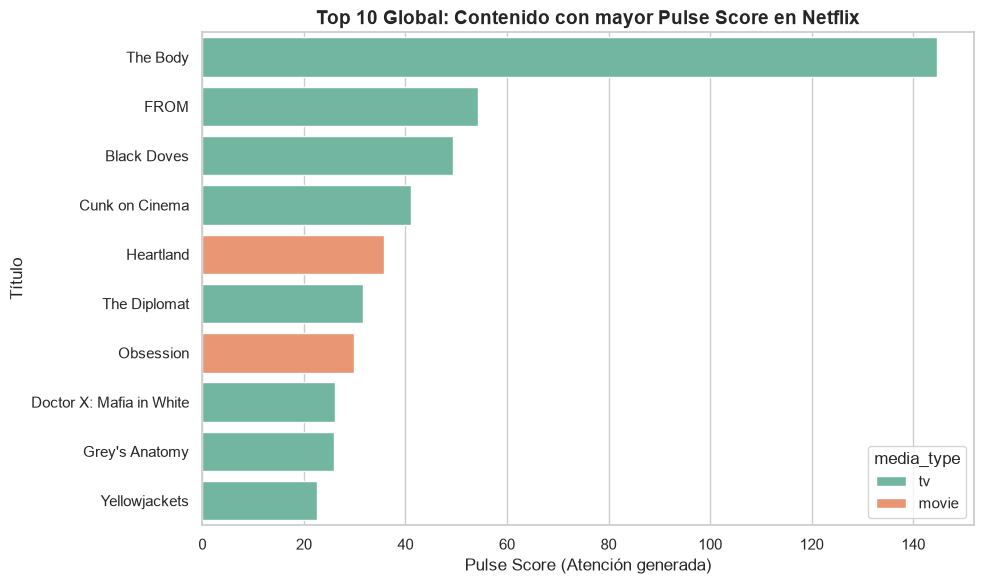

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
#grafico

# Ordenar el dataframe por pulse_score de mayor a menor 
top_10 = df.sort_values(by='pulse_score', ascending=False).head(10)

# Mostrar solo las columnas que nos importan para el negocio
print(top_10[['title', 'media_type', 'pulse_score', 'platform_rank']])


# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Crear la figura
plt.figure(figsize=(10, 6))

# grafico de barras
sns.barplot(data=top_10, x='pulse_score', y='title', hue='media_type', palette='Set2')

# Títulos y etiquetas
plt.title('Top 10 Global: Contenido con mayor Pulse Score en Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Pulse Score (Atención generada)', fontsize=12)
plt.ylabel('Título', fontsize=12)


plt.tight_layout()
#plt.savefig('../outputs/top_10_netflix_pulse.png')
plt.show()